# FNEWS EDA — Model Implications and Responsible Next Steps

EDA informs safeguards, not model selection. The sealed test split is not used for model evaluation or tuning here.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
while not (ROOT / 'reports' / 'EDA').exists(): ROOT = ROOT.parent
EDA = ROOT / 'reports' / 'EDA'
FIG = EDA / 'figures'
summary = json.loads((EDA / 'eda_summary.json').read_text())
summary

{'verified_pairs': 4233,
 'splits': [{'dataset': 'Fakeddit research-v1',
   'split': 'train',
   'manifest_rows': 1185253,
   'verified_pairs': 2353,
   'text_available': 2353,
   'image_available': 2353,
   'raw_label_1_source_true': 1199,
   'raw_label_0_source_non_true': 1154},
  {'dataset': 'Fakeddit research-v1',
   'split': 'validate',
   'manifest_rows': 124425,
   'verified_pairs': 933,
   'text_available': 933,
   'image_available': 933,
   'raw_label_1_source_true': 377,
   'raw_label_0_source_non_true': 556},
  {'dataset': 'Fakeddit research-v1',
   'split': 'test',
   'manifest_rows': 125115,
   'verified_pairs': 947,
   'text_available': 947,
   'image_available': 947,
   'raw_label_1_source_true': 382,
   'raw_label_0_source_non_true': 565}],
 'readable_images': 4233,
 'corrupt_images': 0,
 'exact_text_cross_split_groups': 19,
 'exact_image_cross_split_groups': 0}

### Evidence-backed implications
- Text-length shortcut risk: medians are 48 versus 27 characters.
- Leakage control: 19 exact-text groups cross splits.
- Image integrity: 4233/4233 images decoded.
- Source taxonomy is not factuality verification.

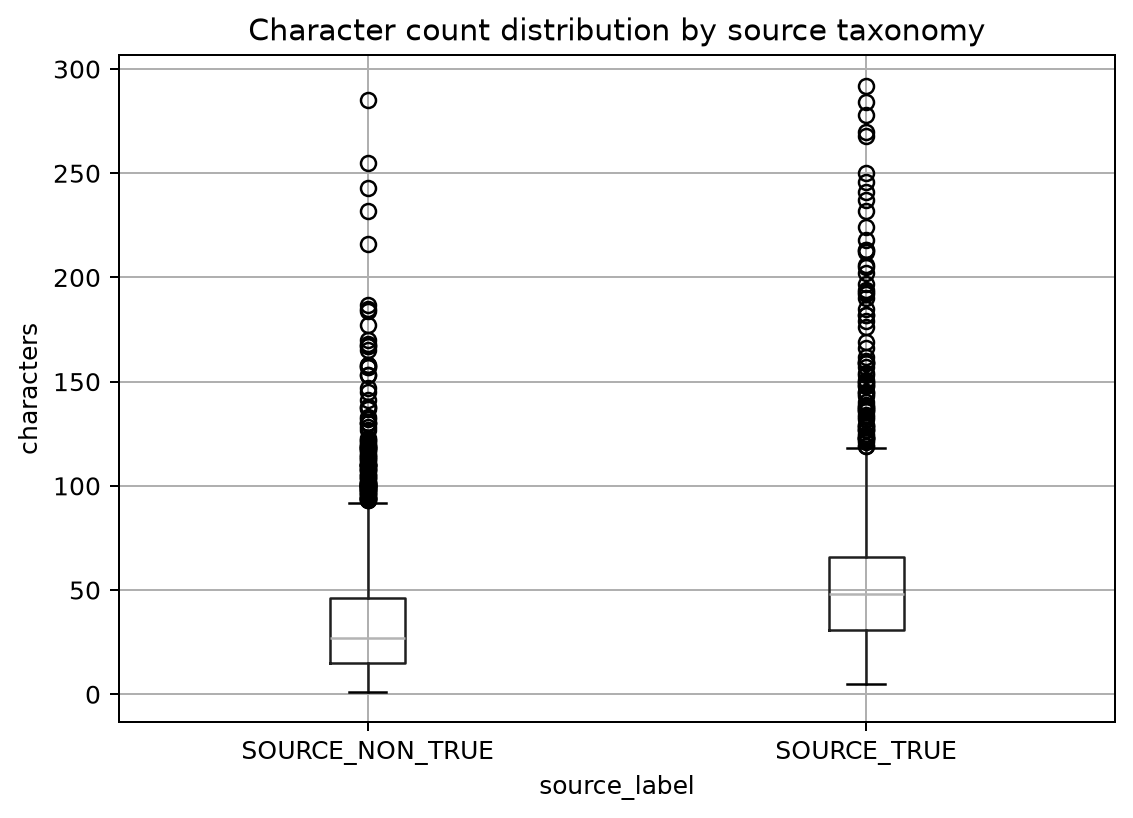

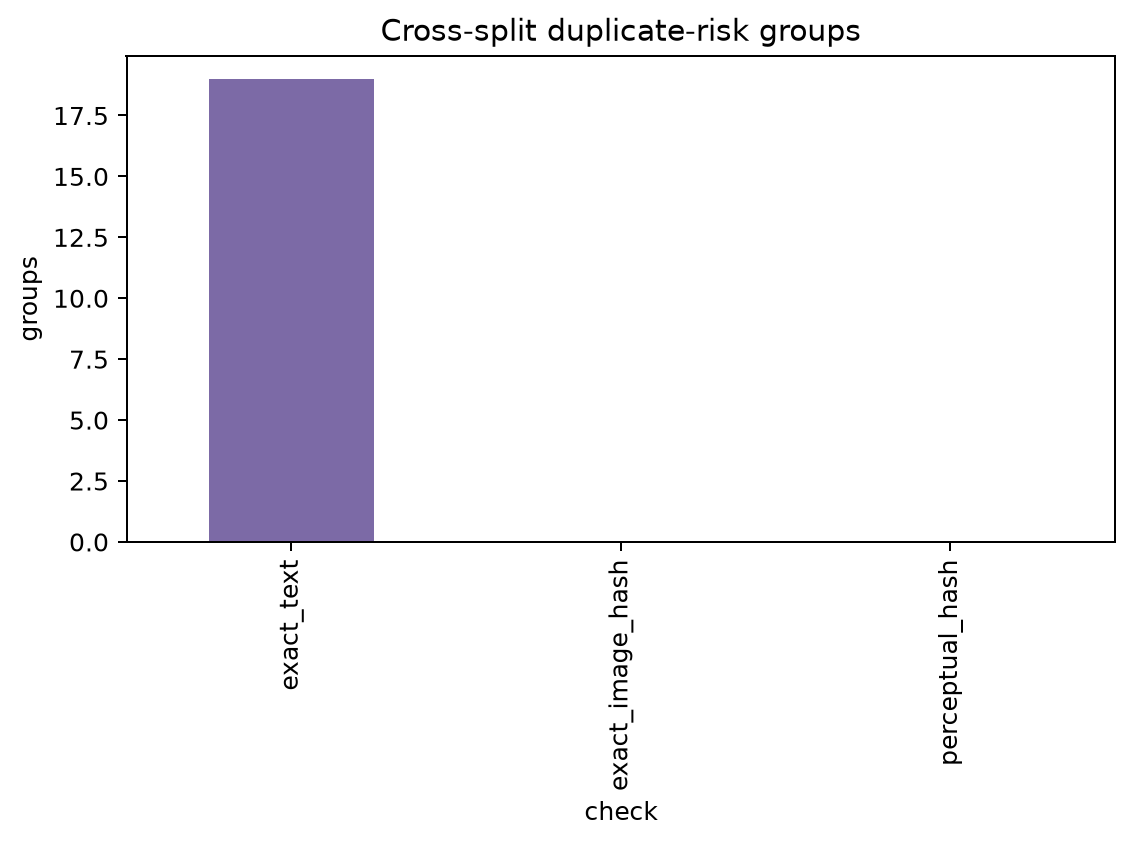

In [2]:
tests=pd.read_csv(EDA/'tables'/'statistical_tests.csv'); leakage=pd.read_csv(EDA/'leakage_audit.csv')
display(Markdown(f'''### Evidence-backed implications
- Text-length shortcut risk: medians are {tests.loc[tests.feature=='chars','median_true'].iloc[0]:.0f} versus {tests.loc[tests.feature=='chars','median_non_true'].iloc[0]:.0f} characters.
- Leakage control: {int(leakage.loc[leakage.check=='exact_text','cross_split_groups'].iloc[0])} exact-text groups cross splits.
- Image integrity: {summary['readable_images']}/{summary['verified_pairs']} images decoded.
- Source taxonomy is not factuality verification.'''))
for n in ['08_chars_boxplot.png','18_leakage_groups.png']: display(Image(filename=str(FIG/n)))

### Reproducibility note

Generated from local manifests and processed images by `scripts/run_comprehensive_eda.py`. No external content was fetched and no model training occurred.